In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

# PART A - TabularQ-learningina4×4GridWorld

In [17]:
rng = np.random.default_rng(42)
ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)
ACTIONS = [(-1, 0), (1, 0), (0,-1), (0, 1)] # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0,-1), "left": (-1, 0), "right": (1, 0)}

def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS- 1), min(max(c + dc, 0), COLS- 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state,-1.0, True
    return next_state,-0.04, False

In [18]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS))) # explore: random move
    return int(np.argmax(Q[state])) # exploit: best known move
    
training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward
        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target- Q[state][action])
        state = next_state
        if done:
            break
    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

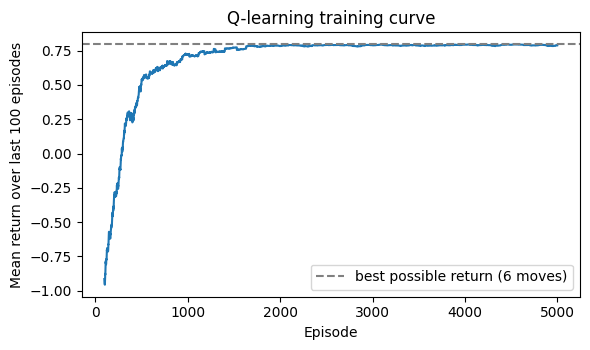

In [19]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")
plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window- 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)
    
print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

success rate: 1.0
mean return: 0.8
learned action at start: down


# PartB— The Q-table is the model:save it and read the policy

In [21]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)
policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
print(policy)

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


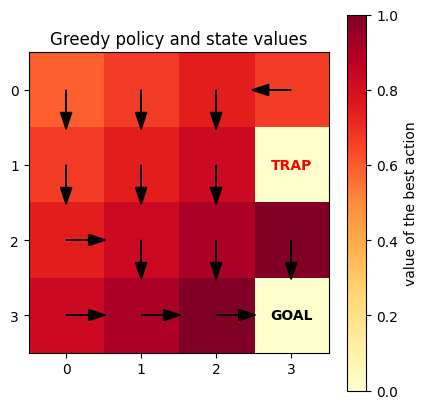

In [23]:
def plot_policy(Q_table, title):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlOrRd")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == TRAP:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx,-0.3 * dy, head_width=0.15, color="black")
                
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()
    
plot_policy(Q_loaded, "Greedy policy and state values")

# Try it Yourself

Modified trap position: (2, 1)
Success rate: 1.0
Mean return: 0.8
Modified policy:
[['down' 'right' 'right' 'down']
 ['right' 'right' 'right' 'down']
 ['up' 'TRAP' 'right' 'down']
 ['right' 'right' 'right' 'GOAL']]


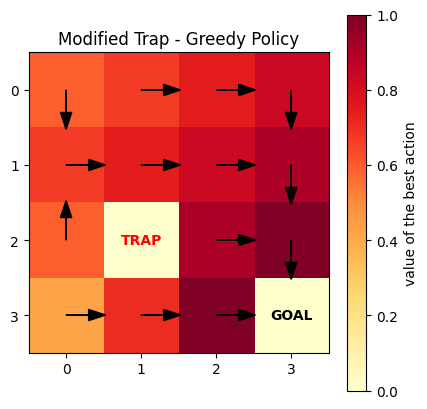

In [25]:
# 1. Change trap position
TRAP = (2, 1)  # Original: (1, 3)

# 2. Reset Q-learning parameters
rng = np.random.default_rng(42)
Q = np.zeros((ROWS, COLS, len(ACTIONS)))

alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05

# 3. Retrain the agent
training_returns = []

for episode in range(5000):
    state, episode_return = START, 0.0

    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)

        episode_return += reward

        target = (
            reward if done
            else reward + gamma * np.max(Q[next_state])
        )

        Q[state][action] += alpha * (
            target - Q[state][action]
        )

        state = next_state

        if done:
            break

    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

# 4. Evaluate modified policy
successes, returns = 0, []

for _ in range(200):
    state, total = START, 0.0

    for _ in range(100):
        state, reward, done = step(
            state, choose_action(state, explore=False)
        )

        total += reward

        if done:
            successes += int(state == GOAL)
            break

    returns.append(total)

print("Modified trap position:", TRAP)
print("Success rate:", successes / 200)
print("Mean return:", round(float(np.mean(returns)), 3))

# 5. Save and reload modified Q-table
q_path = MODELS / "gridworld_q_table_modified.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)

# 6. Display modified policy
policy = np.full((ROWS, COLS), "", dtype=object)

for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = (
            "GOAL" if (r, c) == GOAL
            else "TRAP" if (r, c) == TRAP
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]
        )

print("Modified policy:")
print(policy)

# 7. Display modified heatmap
plot_policy(Q_loaded, "Modified Trap - Greedy Policy")

# Check your understanding

### Question 1: What are the state, action, reward, and transition in a reinforcement-learning formulation?

In reinforcement learning, the state represents the agent's current position or situation in the environment. An action is the decision the agent makes, such as moving up, down, left, or right. A reward is the feedback received after taking an action, which helps the agent learn whether the action is good or bad. A transition occurs when the agent moves from its current state to the next state after performing an action.

The agent receives +1 for reaching the goal, −1 for entering the trap, and −0.04 for an ordinary move.

### Question 2: What two pieces of information appear in the tabular Q-learning backup value?

The two pieces of information are the immediate reward received after taking an action and the discounted maximum future Q-value from the next state.

The Q-learning target is calculated using:

\\[ \text{Target}=r+\gamma\max\_{a'}Q(s',a') \\]

Where:

- \\(r\\) = immediate reward
- \\(\gamma\\) = discount factor
- \\(Q(s',a')\\) = estimated future reward for an action in the next state

For terminal states, the target uses only the immediate reward because there are no future actions.

### Question 3: Why should the exploratory training policy be evaluated separately from the final greedy policy?

The exploratory training policy should be evaluated separately because the agent takes random actions during training to discover better routes. These random actions may reduce its performance even after it has learned a good policy.

The final greedy policy always selects the action with the highest Q-value without random exploration. Evaluating it separately allows us to measure how well the agent has learned to reach the goal.

In this lab, the greedy policy achieved a 100% success rate and a mean return of 0.80, showing that the agent successfully learned the shortest route to the goal.